Total Cases Loaded: 220


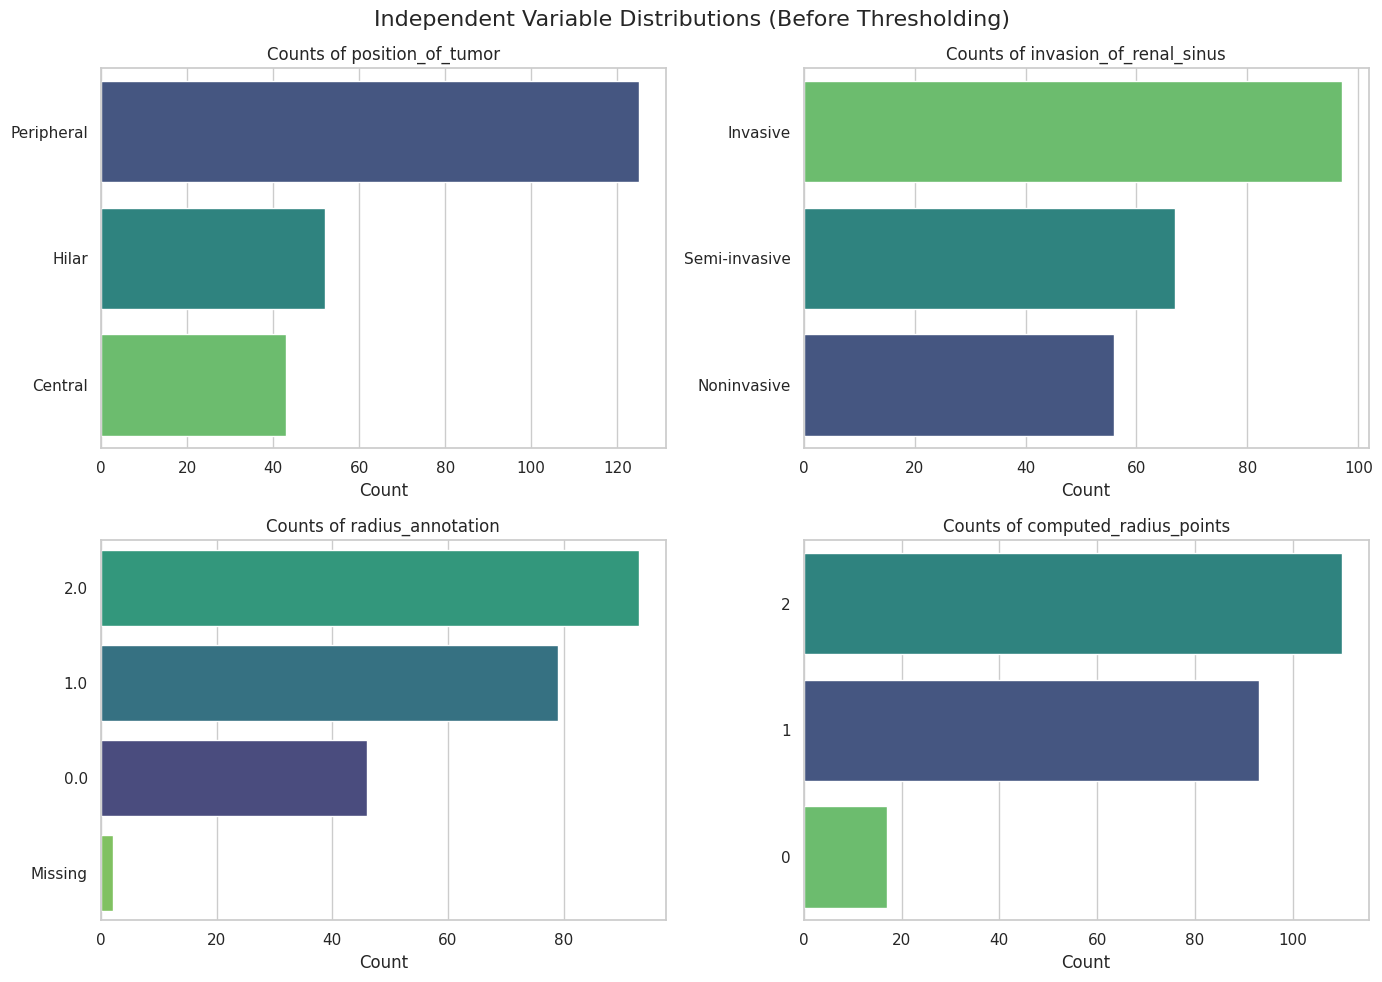

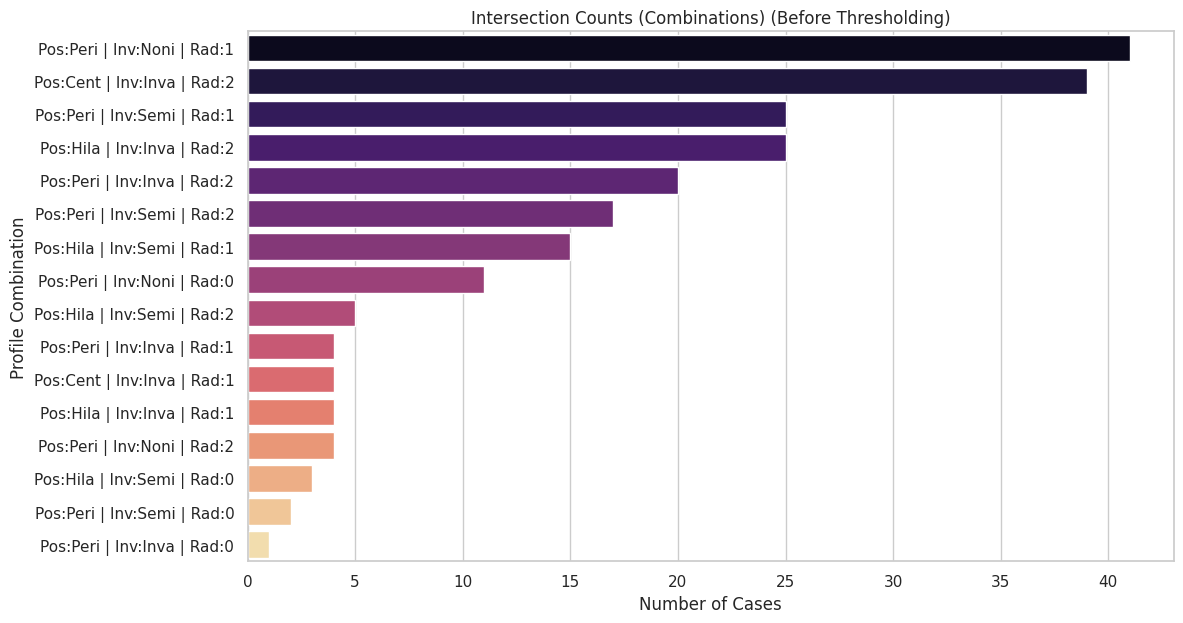

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from modules import data_preprocessing as dataPrep

# 1. Load Data
PROCESSED_DATA_DIR = Path('/home/marcel/Repos/Data/kits23_processed')
labels_df = pd.read_csv(PROCESSED_DATA_DIR / "labels.csv")

# 2. Compute Radius Labels
dataPrep.compute_radius_from_diameter(labels_df)

def plot_metadata_stats(df, title_suffix=""):
    """Plots independent variable counts and their combinatorial intersections."""
    sns.set_theme(style="whitegrid")
    
    # Variables to analyze
    cat_vars = ['position_of_tumor', 'invasion_of_renal_sinus', 'radius_annotation', 'computed_radius_points']
    
    # --- PART 1: Independent Counts ---
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Independent Variable Distributions {title_suffix}", fontsize=16)
    axes = axes.flatten()
    
    for i, var in enumerate(cat_vars):
        # Fill NaNs temporarily for plotting so they don't disappear
        plot_data = df[var].fillna('Missing').astype(str)
        
        # FIX: Assigned `hue=plot_data` and `legend=False` to silence the warning
        sns.countplot(
            y=plot_data, 
            hue=plot_data, 
            ax=axes[i], 
            order=plot_data.value_counts().index, 
            palette="viridis", 
            legend=False
        )
        axes[i].set_title(f"Counts of {var}")
        axes[i].set_xlabel("Count")
        axes[i].set_ylabel("")
        
    plt.tight_layout()
    plt.show()

    # --- PART 2: Intersections (Combinations) ---
    # Using position, invasion, and computed_radius (ignoring original radius to avoid clutter/NaNs)
    combo_cols = ['position_of_tumor', 'invasion_of_renal_sinus', 'computed_radius_points']
    
    # Group by the combination of these columns and count
    combinations = df.groupby(combo_cols, dropna=False).size().reset_index(name='count')
    combinations = combinations.sort_values('count', ascending=False)
    
    # Create a readable string label for the combinations
    combinations['combo_label'] = combinations.apply(
        lambda r: f"Pos:{str(r['position_of_tumor'])[:4]} | Inv:{str(r['invasion_of_renal_sinus'])[:4]} | Rad:{r['computed_radius_points']}", 
        axis=1
    )
    
    plt.figure(figsize=(12, max(6, len(combinations) * 0.4)))
    
    # FIX: Assigned `hue='combo_label'` and `legend=False`
    sns.barplot(
        x='count', 
        y='combo_label', 
        hue='combo_label', 
        data=combinations, 
        palette="magma", 
        legend=False
    )
    plt.title(f"Intersection Counts (Combinations) {title_suffix}")
    plt.xlabel("Number of Cases")
    plt.ylabel("Profile Combination")
    plt.tight_layout()
    plt.show()

print(f"Total Cases Loaded: {len(labels_df)}")
plot_metadata_stats(labels_df, "(Before Thresholding)")

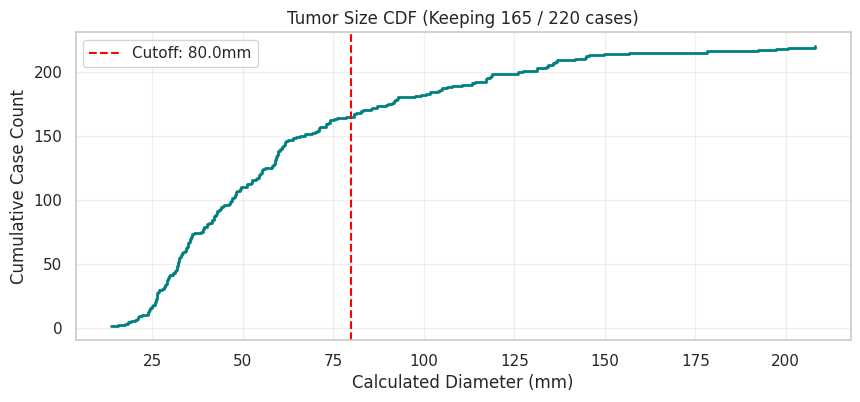

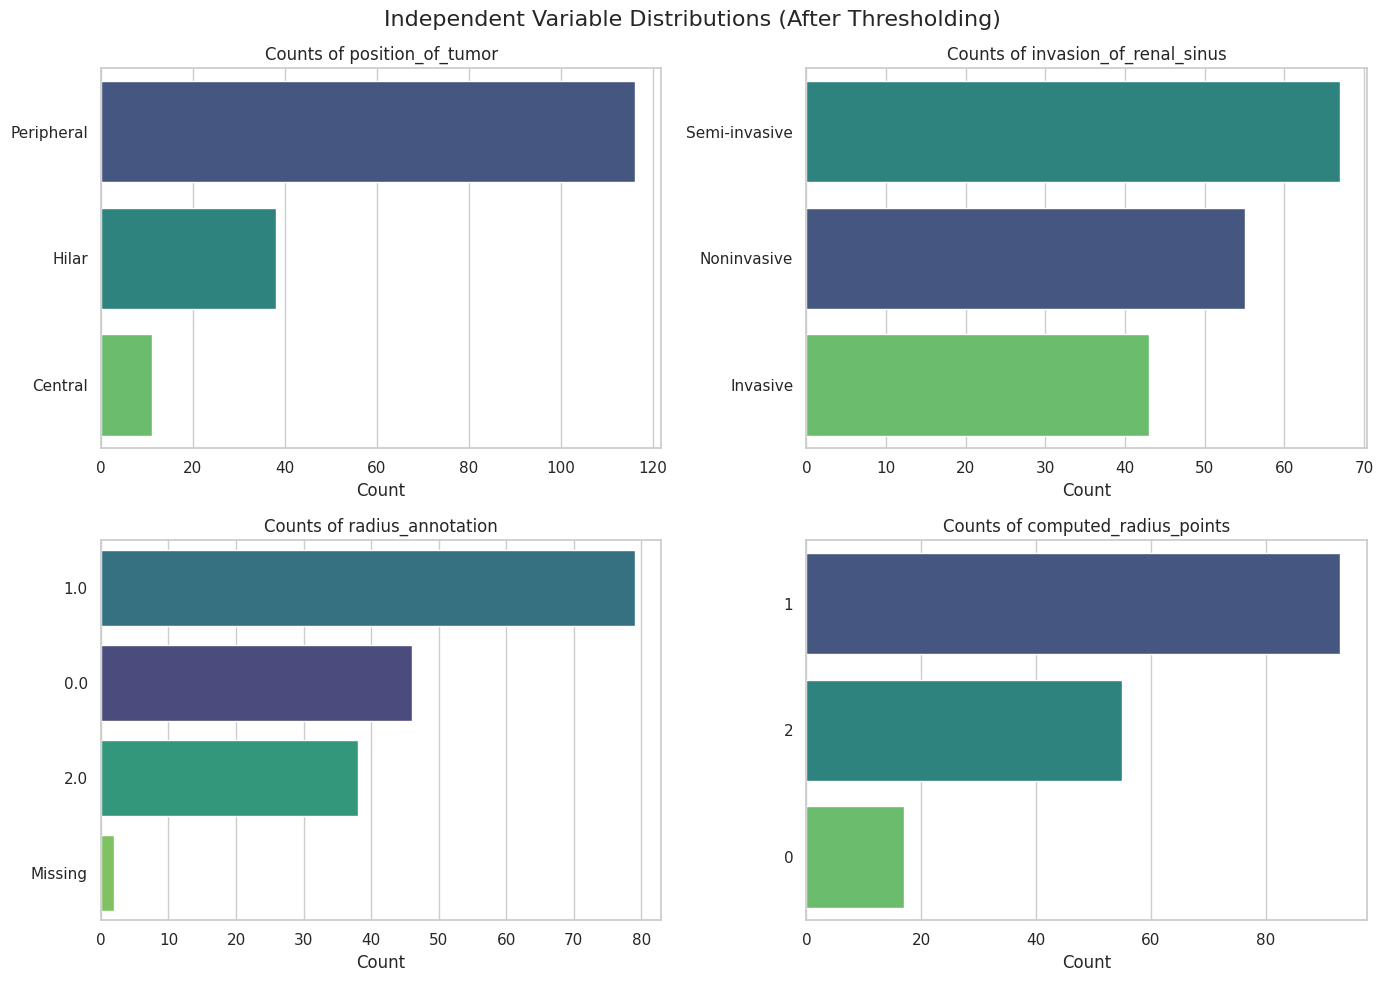

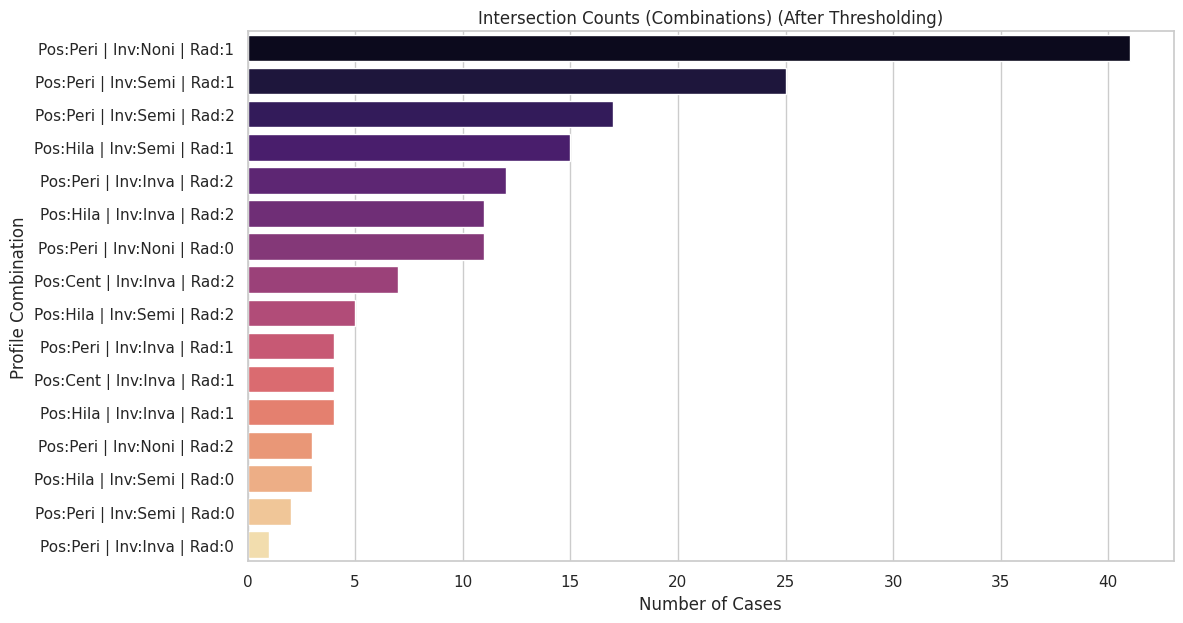

In [ ]:
def apply_threshold_and_plot(df, threshold=100.0):
    sorted_diameters = np.sort(df['calculated_diameter_mm'].dropna())
    y_vals = np.arange(1, len(sorted_diameters) + 1)
    
    # Plot CDF
    plt.figure(figsize=(10, 4))
    plt.step(sorted_diameters, y_vals, color='teal', where='post', linewidth=2)
    plt.axvline(x=threshold, color='red', linestyle='--', label=f'Cutoff: {threshold}mm')
    
    # Filter dataset
    kept_df = df[df['calculated_diameter_mm'] <= threshold].copy()
    
    plt.title(f"Tumor Size CDF (Keeping {len(kept_df)} / {len(df)} cases)")
    plt.xlabel("Calculated Diameter (mm)")
    plt.ylabel("Cumulative Case Count")
    plt.legend()
    plt.show()
    
    return kept_df

# SET YOUR THRESHOLD HERE
THRESHOLD_MM = 80.0 
filtered_df = apply_threshold_and_plot(labels_df, threshold=THRESHOLD_MM)

# Plot stats again to see what survived the threshold cut
plot_metadata_stats(filtered_df, "(After Thresholding)")

In [7]:
from scipy.ndimage import label, center_of_mass

def extract_system_bbox(case_id):
    mask_path = PROCESSED_DATA_DIR / f"{case_id}.npy"
    if not mask_path.exists():
        print(f"[ERROR] Missing file for case: {case_id}")
        return None
        
    mask = np.load(mask_path)
    
    # Identify classes
    kidney_mask = (mask == 1).astype(np.int8)
    tumor_mask = (mask == 2).astype(np.int8)
    
    if not np.any(tumor_mask):
        print(f"[FLAG] Case {case_id}: No tumor pixels found in mask.")
        return None

    # 1. Calculate Tumor Center of Mass
    tumor_com = center_of_mass(tumor_mask)

    # 2. Label kidneys and find the largest bodies
    labeled_kidneys, num_features = label(kidney_mask)
    if num_features == 0:
        print(f"[FLAG] Case {case_id}: No kidney pixels found in mask.")
        return None
        
    # Count pixels per label (index 0 is background)
    component_sizes = np.bincount(labeled_kidneys.ravel())
    component_sizes[0] = 0 # Ignore background size
    
    # Get the labels of the up to 2 largest components
    # (Using [-2:] gets the last two elements of the sorted array)
    top_labels = np.argsort(component_sizes)[-2:]
    # Filter out any that might have size 0 (e.g., if there's only 1 kidney)
    top_labels = [lbl for lbl in top_labels if component_sizes[lbl] > 0]
    
    # 3. Find the kidney body closest to the tumor
    min_dist = float('inf')
    closest_kidney_label = None
    
    for lbl in top_labels:
        kidney_com = center_of_mass(labeled_kidneys == lbl)
        
        # Euclidean distance between CoMs
        dist = np.linalg.norm(np.array(tumor_com) - np.array(kidney_com))
        
        if dist < min_dist:
            min_dist = dist
            closest_kidney_label = lbl

    if closest_kidney_label is None:
        return None

    # 4. Create the final system mask
    relevant_kidney = (labeled_kidneys == closest_kidney_label).astype(np.int8)
    system_mask = (relevant_kidney | tumor_mask)
    
    # 5. Calculate Bounding Box
    coords = np.argwhere(system_mask > 0)
    z_min, y_min, x_min = coords.min(axis=0)
    z_max, y_max, x_max = coords.max(axis=0)
    
    return {
        'case_id': case_id,
        'bb_z_px': z_max - z_min,
        'bb_y_px': y_max - y_min,
        'bb_x_px': x_max - x_min,
        'sys_z_min': z_min, 'sys_z_max': z_max,
        'sys_y_min': y_min, 'sys_y_max': y_max,
        'sys_x_min': x_min, 'sys_x_max': x_max
    }

# Execute spatial cleaning
bbox_results = []
for cid in tqdm(filtered_df['case_id'], desc="Extracting Bounding Boxes"):
    res = extract_system_bbox(cid)
    if res:
        bbox_results.append(res)

bbox_df = pd.DataFrame(bbox_results)
final_df = pd.merge(filtered_df, bbox_df, on='case_id')
print(f"Successfully extracted bounding boxes for {len(final_df)} cases.")

Extracting Bounding Boxes: 100%|██████████| 165/165 [06:38<00:00,  2.41s/it]

Successfully extracted bounding boxes for 165 cases.


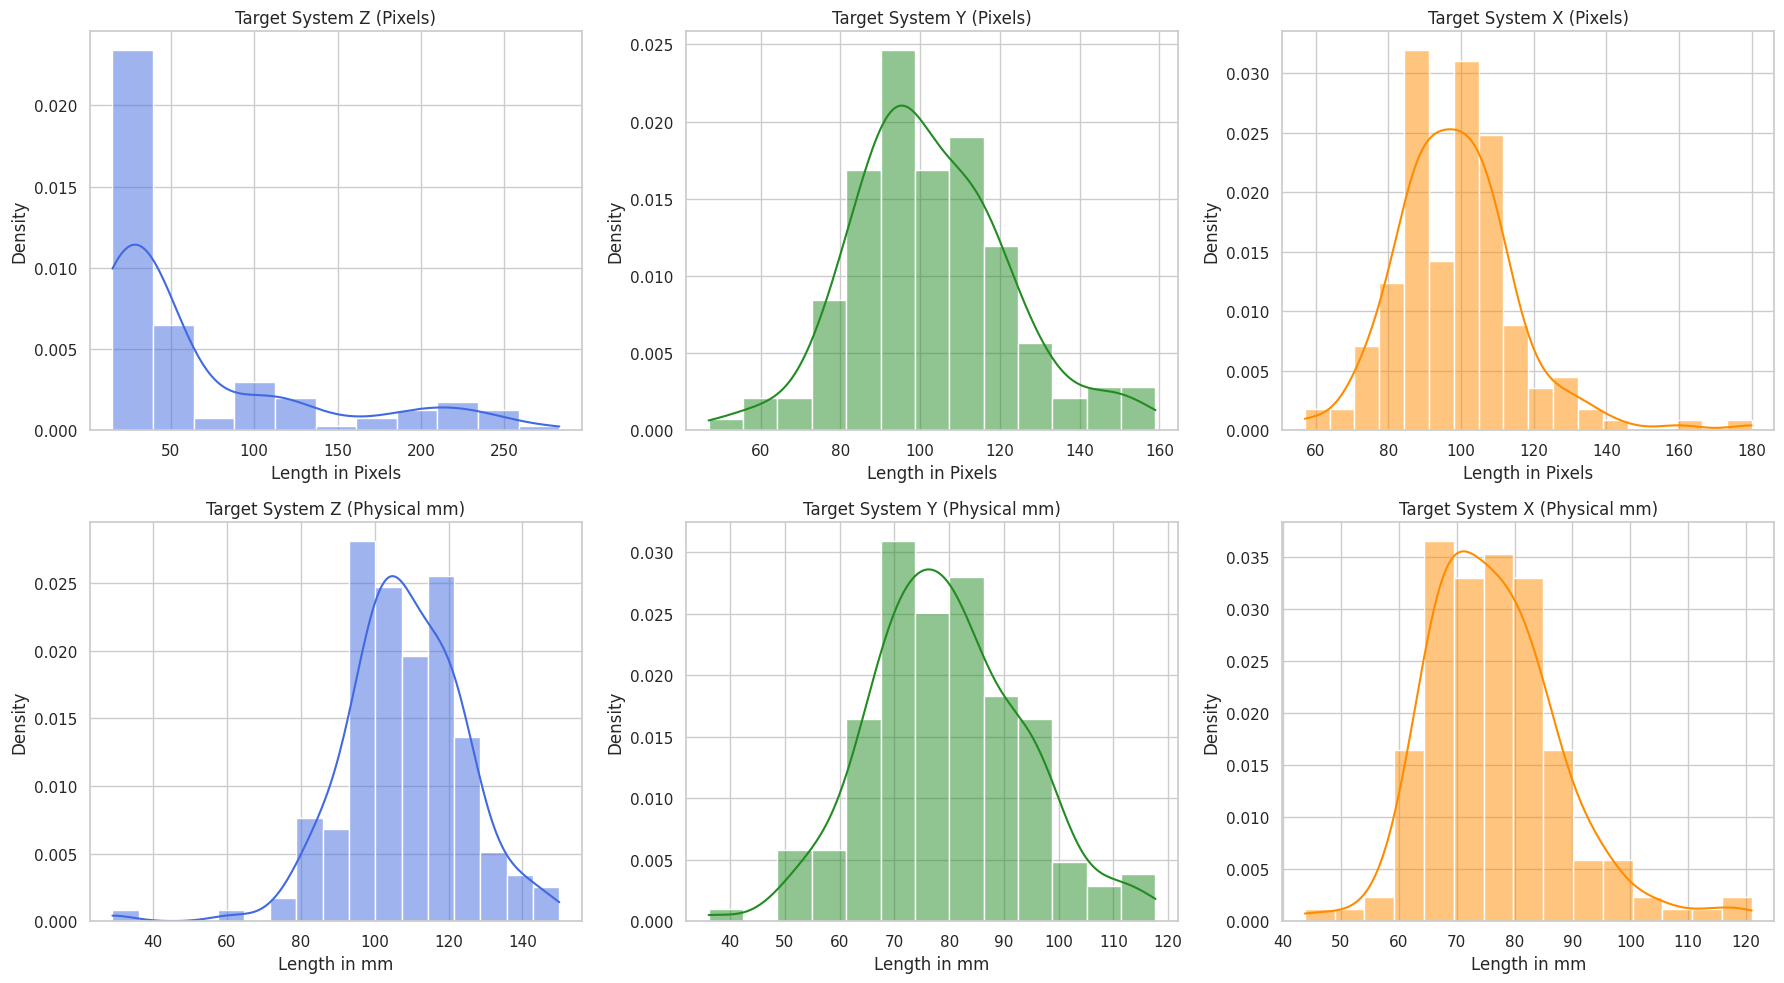


--- Summary Stats for Final Crop Dimensions ---
       bb_z_px  bb_y_px  bb_x_px  bb_z_mm  bb_y_mm  bb_x_mm
count   165.00   165.00   165.00   165.00   165.00   165.00
mean     63.84   102.39    98.58   108.05    79.45    76.51
std      65.34    19.66    16.63    16.20    13.98    11.55
min      15.00    47.00    57.00    29.00    36.08    43.75
25%      22.00    90.00    88.00   100.00    70.52    67.92
50%      34.00   100.00    98.00   106.50    78.67    75.20
75%      93.00   115.00   107.00   120.00    88.16    82.65
max     283.00   159.00   180.00   150.00   117.68   120.98


In [8]:
# Calculate Physical Dimensions
final_df['bb_z_mm'] = final_df['bb_z_px'] * final_df['spacing_z']
final_df['bb_y_mm'] = final_df['bb_y_px'] * final_df['spacing_y']
final_df['bb_x_mm'] = final_df['bb_x_px'] * final_df['spacing_x']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Pixel Dimensions
dims = ['z', 'y', 'x']
colors = ['royalblue', 'forestgreen', 'darkorange']

for i, (dim, color) in enumerate(zip(dims, colors)):
    sns.histplot(final_df[f'bb_{dim}_px'], ax=axes[0, i], kde=True, color=color, stat='density')
    axes[0, i].set_title(f"Target System {dim.upper()} (Pixels)")
    axes[0, i].set_xlabel("Length in Pixels")

# 2. Physical Dimensions
for i, (dim, color) in enumerate(zip(dims, colors)):
    sns.histplot(final_df[f'bb_{dim}_mm'], ax=axes[1, i], kde=True, color=color, stat='density')
    axes[1, i].set_title(f"Target System {dim.upper()} (Physical mm)")
    axes[1, i].set_xlabel("Length in mm")

plt.tight_layout()
plt.show()

# Display summary statistics for making keras crop decisions
print("\n--- Summary Stats for Final Crop Dimensions ---")
print(final_df[['bb_z_px', 'bb_y_px', 'bb_x_px', 'bb_z_mm', 'bb_y_mm', 'bb_x_mm']].describe().round(2))

In [13]:
def search_cases(df, pos=None, inv=None, rad=None, max_diameter=None):
    """
    Filters the dataframe for specific clinical profiles.
    Leave a parameter as None if you don't want to filter by it.
    """
    # Start with a mask where everything is True
    mask = pd.Series(True, index=df.index)
    
    # Apply filters dynamically
    if pos is not None:
        mask &= (df['position_of_tumor'] == pos)
    if inv is not None:
        mask &= (df['invasion_of_renal_sinus'] == inv)
    if rad is not None:
        mask &= (df['computed_radius_points'] == rad)
    if max_diameter is not None:
        mask &= (df['calculated_diameter_mm'] <= max_diameter)
        
    results = df[mask].copy()
    
    print(f"--- Search Results ---")
    print(f"Found {len(results)} cases matching your criteria:")
    if pos is not None: print(f"  - Position: {pos}")
    if inv is not None: print(f"  - Sinus Invasion: {inv}")
    if rad is not None: print(f"  - Radius Points: {rad}")
    if max_diameter is not None: print(f"  - Max Diameter: {max_diameter}mm")
    print("-" * 22)
    
    return results

# ==========================================
# USAGE AREA: Edit the variables below
# ==========================================

# If you need a reminder of the exact text labels, uncomment these lines:
print("Available Positions:", labels_df['position_of_tumor'].dropna().unique())
print("Available Invasions:", labels_df['invasion_of_renal_sinus'].dropna().unique())

TARGET_POS = 'Peripheral'
TARGET_INV = 'Invasive'
TARGET_RAD = 0
MAX_DIAMETER = None

# Search within the original dataset (or change to filtered_df)
found_cases = search_cases(
    labels_df, 
    pos=TARGET_POS, 
    inv=TARGET_INV, 
    rad=TARGET_RAD, 
    max_diameter=MAX_DIAMETER
)

# Display the resulting case IDs so you can copy them into 3D Slicer
if not found_cases.empty:
    display(found_cases[['case_id', 'position_of_tumor', 'invasion_of_renal_sinus', 'computed_radius_points', 'calculated_diameter_mm']].head(10))

Available Positions: <StringArray>
['Peripheral', 'Hilar', 'Central']
Length: 3, dtype: str
Available Invasions: <StringArray>
['Noninvasive', 'Semi-invasive', 'Invasive']
Length: 3, dtype: str
--- Search Results ---
Found 1 cases matching your criteria:
  - Position: Peripheral
  - Sinus Invasion: Invasive
  - Radius Points: 0
----------------------


,case_id,position_of_tumor,invasion_of_renal_sinus,computed_radius_points,calculated_diameter_mm
16,case_00023,Peripheral,Invasive,0,24.91
